# GraspGenX with our 4-finger gripper, on objects it has never seen

The companion notebook `graspgenx_unseen_objects.ipynb` does this with our 2-finger fin-ray
gripper. This one swaps in the **4-finger** version — the same body and the same fingers, with
two more added on the other axis — and asks the same two questions:

1. Does GraspGenX still produce grasps for objects outside its training set?
2. Do all **four** fingers actually reach the object, or only two of them?

Question 2 is the one that matters. GraspGenX was trained on parallel-jaw grippers, and its
gripper conditioning is a swept-volume box. A 4-finger gripper and a very wide 2-finger gripper
describe almost the same box, so the model has no way to know that two extra fingers are closing
from the sides.

Everything runs on the Mac CPU, about 2 seconds per object.

## 1. Setup

In [1]:
import json, os, pathlib, subprocess, time
import numpy as np, trimesh, matplotlib.pyplot as plt

os.environ["GRASPGENX_DEVICE"] = "cpu"   # MPS gives wrong numbers for this model

from graspgenx import get_checkpoints_version_dir
from graspgenx.grasp_server import GraspGenXSampler
from graspgenx.utils.checkpoint_io import load_model_cfg
from graspgenx.x_grippers import make_sweep_volume_gripper_info, resolve_gripper_info

ROOT = pathlib.Path.cwd()
YCB  = ROOT/"data"/"ycb"
OUT  = ROOT/"stage2_grasp"/"results"; OUT.mkdir(exist_ok=True)

OBJECTS = ["002_master_chef_can", "005_tomato_soup_can", "006_mustard_bottle",
           "011_banana", "021_bleach_cleanser", "025_mug", "035_power_drill",
           "037_scissors", "048_hammer", "055_baseball"]
print(len(OBJECTS), "objects")

2026-09-11 09:25:30,008 - OpenGL.acceleratesupport - INFO - OpenGL_accelerate module loaded


2026-09-11 09:25:30,025 - OpenGL.arrays.arraydatatype - INFO - Using accelerated ArrayDatatype


2026-09-11 09:25:30,148 - graspgenx.dataset.dataset - WARNING - Could not import renderer (pyrender): dlsym(0x330bff124, class_getMethodImplementation_stret): symbol not found. Rendering functions will be unavailable (OK for training).


/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/pointnet/pointnet2_utils.py:23: UserWarning: Unable to load pointnet2_ops cpp extension. JIT Compiling.
  warnings.warn("Unable to load pointnet2_ops cpp extension. JIT Compiling.")
/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/pointnet/pointnet2_utils.py:40: UserWarning: Unable to import PointNet++ backbone (pointnet2_ops). PointNet++ models will not be available. Other backbones (e.g. WarpConvNet) are unaffected.
  warnings.warn(


10 objects


The meshes come from the YCB benchmark. This downloads them once (~140 MB).

In [2]:
BASE = "http://ycb-benchmarks.s3-website-us-east-1.amazonaws.com/data/google"
for name in OBJECTS:
    if (YCB/name).exists():
        continue
    YCB.mkdir(parents=True, exist_ok=True)
    tgz = YCB/f"{name}.tgz"
    subprocess.run(["curl", "-sfL", f"{BASE}/{name}_google_16k.tgz", "-o", str(tgz)], check=True)
    subprocess.run(["tar", "xzf", str(tgz), "-C", str(YCB)], check=True)
    tgz.unlink()
    print("downloaded", name)

print("meshes ready:", len(list(YCB.glob("*/google_16k/nontextured.ply"))))

meshes ready: 26


## 2. Are these objects really unseen?

GraspGenX's splits list Objaverse assets by UUID. YCB objects are scans of real products from a
different dataset, so they cannot appear in those lists. We check it rather than assume it.

In [3]:
seen = set()
for f in (ROOT/"data"/"objaverse"/"splits").glob("*/valid.txt"):
    seen |= {l.strip() for l in open(f) if l.strip()}

print(f"{len(seen)} object ids in the GraspGen splits, e.g. {list(seen)[0]}")
print("overlap with our YCB objects:", seen & set(OBJECTS))

1224 object ids in the GraspGen splits, e.g. 0daf244070a24a24ab29d0d6f86977ef
overlap with our YCB objects: set()


## 3. Our 4-finger gripper

The numbers come from the same measured file as the 2-finger version. The only thing that changes
is the **y** extent of the swept volume: 30 mm for two fingers, 148 mm for four, because the second
pair closes along the other axis.

That means the four fingers sit in a cross — at +x, -x, +y and -y — all of them 74 mm out from the
centre when open.

In [4]:
params = json.load(open(ROOT/"data"/"gripper"/"params_legacy.json"))
g = params["grippers"]["4-finger"]
assert g["n_contacts"] == 4

gripper = make_sweep_volume_gripper_info(
    g["extents_open"], g["offset_open"],
    g["extents_mid"],  g["offset_mid"],
    name="finray_4f",
)

REACH  = g["extents_open"][0]/2                             # 74 mm from centre to each finger
Z_TIP  = g["offset_open"][2] + g["extents_open"][2]/2       # front of the swept box
Z_BACK = g["offset_open"][2] - g["extents_open"][2]/2       # back of it
FINGERS = np.array([[1,0], [-1,0], [0,1], [0,-1]], float)   # where the four fingers sit

print(f"2-finger swept box : {[round(v*1000,1) for v in params['grippers']['2-finger']['extents_open']]} mm")
print(f"4-finger swept box : {[round(v*1000,1) for v in g['extents_open']]} mm")
print(f"each finger sits {REACH*1000:.1f} mm from the centre, "
      f"reaching z = {Z_BACK*1000:.1f}..{Z_TIP*1000:.1f} mm")

2-finger swept box : [148.1, 30.0, 38.3] mm
4-finger swept box : [148.1, 148.1, 38.3] mm
each finger sits 74.1 mm from the centre, reaching z = 75.8..114.0 mm


## 4. Load the model

In [5]:
ckpt = get_checkpoints_version_dir()
cfg  = load_model_cfg(str(ckpt/"gen"), str(ckpt/"dis"))
sampler = GraspGenXSampler(cfg, gripper_info=gripper)
print("ready")

Generator checkpoint : /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/gen/epoch_736.pth
Discriminator checkpoint: /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/dis/epoch_1056.pth
Generator      : backbone=ptv3vanilla, gripper=sweep_volume_v2, obj_dim=512, embed_dim=512, pointnet_ver=v2
  DDPM         : train_steps=20, eval_steps=20, beta_schedule=squaredcos_cap_v2, clip_sample=True, compositional=True
  Grasp        : grasp_repr=r3_so3, kappa(noise_scale)=3.27, pose_repr=mlp
Discriminator  : backbone=ptv3vanilla, gripper=sweep_volume_v2, obj_dim=512, embed_dim=256, pointnet_ver=v2
  Grasp        : grasp_repr=r3_so3, kappa(noise_scale)=3.27, pose_repr=mlp


/opt/anaconda3/envs/graspgenx/lib/python3.12/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


2026-09-11 09:25:31,889 - graspgenx.models.discriminator - INFO - Pose representation is mlp


2026-09-11 09:25:31,891 - graspgenx.models.grasp_gen - INFO - Loading generator checkpoint from /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/gen/epoch_736.pth


2026-09-11 09:25:32,898 - graspgenx.models.grasp_gen - INFO - Loading discriminator checkpoint from /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/dis/epoch_1056.pth


ready


## 5. Run inference

Same as the 2-finger notebook: 3500 points off the mesh surface, centred, two sampling passes
keeping the 20 best each.

In [6]:
def grasps_for(name, n_keep=20):
    mesh = trimesh.load(YCB/name/"google_16k"/"nontextured.ply", force="mesh")
    pts, _ = trimesh.sample.sample_surface(mesh, 3500)
    pts = np.asarray(pts, dtype=np.float32)
    centre = pts.mean(0)
    pts -= centre                           # the model expects a centred cloud
    mesh.apply_translation(-centre)         # keep the mesh in the same frame
    dense = np.asarray(trimesh.sample.sample_surface(mesh, 40000)[0]) - centre

    poses, conf = GraspGenXSampler.run_inference(
        pts, sampler, grasp_threshold=-1.0, num_grasps=200,
        topk_num_grasps=n_keep, remove_outliers=False,
    )
    return pts, poses.cpu().numpy(), conf.cpu().numpy(), mesh, dense


results = {}
for name in OBJECTS:
    t = time.time()
    pts, poses, conf, mesh, dense = grasps_for(name)
    results[name] = dict(pts=pts, poses=poses, conf=conf, mesh=mesh, dense=dense,
                         size=mesh.extents*1000)
    print(f"{name:22s} {len(poses):3d} grasps   "
          f"confidence {conf.min():.2f}-{conf.max():.2f}   {time.time()-t:.1f}s")

/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/generator.py:853: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.sqrt(torch.tensor(var_pos, device=device)),
/Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/graspgenx/models/generator.py:865: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.sqrt(torch.tensor(var_rot, device=device)),


2026-09-11 09:25:34,507 - graspgenx.grasp_server - INFO - Confidences min: 0.00332, max: 0.91232


2026-09-11 09:25:34,507 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:25:34,511 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 1, total grasps: 20


2026-09-11 09:25:34,511 - graspgenx.grasp_server - INFO - Time taken for inference: 1.1514759063720703 seconds


...

2026-09-11 09:25:51,600 - graspgenx.grasp_server - INFO - Confidences min: 0.01427, max: 0.98053


2026-09-11 09:25:51,600 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:25:51,603 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 2, total grasps: 40


2026-09-11 09:25:51,603 - graspgenx.grasp_server - INFO - Time taken for inference: 0.7773761749267578 seconds


055_baseball            40 grasps   confidence 0.96-0.99   1.6s


## 6. Where do the fingers actually end up?

The swept volume tells us exactly where the fingers are: they occupy z = 76 to 114 mm in front of
the gripper base. So for any grasp we can transform the object into the gripper frame and ask a
blunt question — **does the object reach the fingers at all?**

We call the answer the *standoff*: how far the nearest part of the object sits beyond the
fingertips. Zero or less means the fingers are on the object. A positive standoff means the
gripper stopped short and would close on empty air.

In [7]:
def standoff_mm(pose, dense):
    """How far past the fingertips the object begins (mm). <= 0 means the fingers reach it."""
    Ti = np.linalg.inv(pose)
    p = dense @ Ti[:3, :3].T + Ti[:3, 3]              # object seen from the gripper
    return (p[:, 2].min() - Z_TIP) * 1000


def four_contacts(pose, dense):
    """Where each of the four fingers would touch, for grasps that do reach the object."""
    Ti = np.linalg.inv(pose)
    p = dense @ Ti[:3, :3].T + Ti[:3, 3]
    band = (p[:, 2] >= Z_BACK) & (p[:, 2] <= Z_TIP)
    if band.sum() < 10:
        return None
    q = p[band]
    contacts = [q[int(np.argmax(q[:, 0]*fx + q[:, 1]*fy))] for fx, fy in FINGERS]
    return np.array(contacts) @ pose[:3, :3].T + pose[:3, 3]


for name in OBJECTS:
    r = results[name]
    r["standoff"] = np.array([standoff_mm(T, r["dense"]) for T in r["poses"]])
    print(f"{name[4:].replace('_',' '):18s} standoff "
          f"{np.median(r['standoff']):6.1f} mm    "
          f"{np.mean(r['standoff'] <= 0):4.0%} of grasps reach the object")

master chef can    standoff   25.2 mm      8% of grasps reach the object
tomato soup can    standoff   31.1 mm     32% of grasps reach the object
mustard bottle     standoff   23.7 mm      8% of grasps reach the object
banana             standoff   41.8 mm      2% of grasps reach the object


bleach cleanser    standoff   46.9 mm      8% of grasps reach the object
mug                standoff   19.0 mm      8% of grasps reach the object


power drill        standoff   31.5 mm     38% of grasps reach the object
scissors           standoff   27.2 mm      0% of grasps reach the object
hammer             standoff  -25.3 mm     70% of grasps reach the object
baseball           standoff   39.2 mm      8% of grasps reach the object


## 7. Collage

Grey dots are the object. The blue cross is the highest-confidence grasp drawn with all four
fingers; orange is the second-highest. Red dots mark the four contact points, drawn only when the
blue grasp reaches far enough to have any.

Each title gives the object, its shortest bounding-box side, the confidence GraspGenX gave the blue
grasp, and that same grasp's standoff.

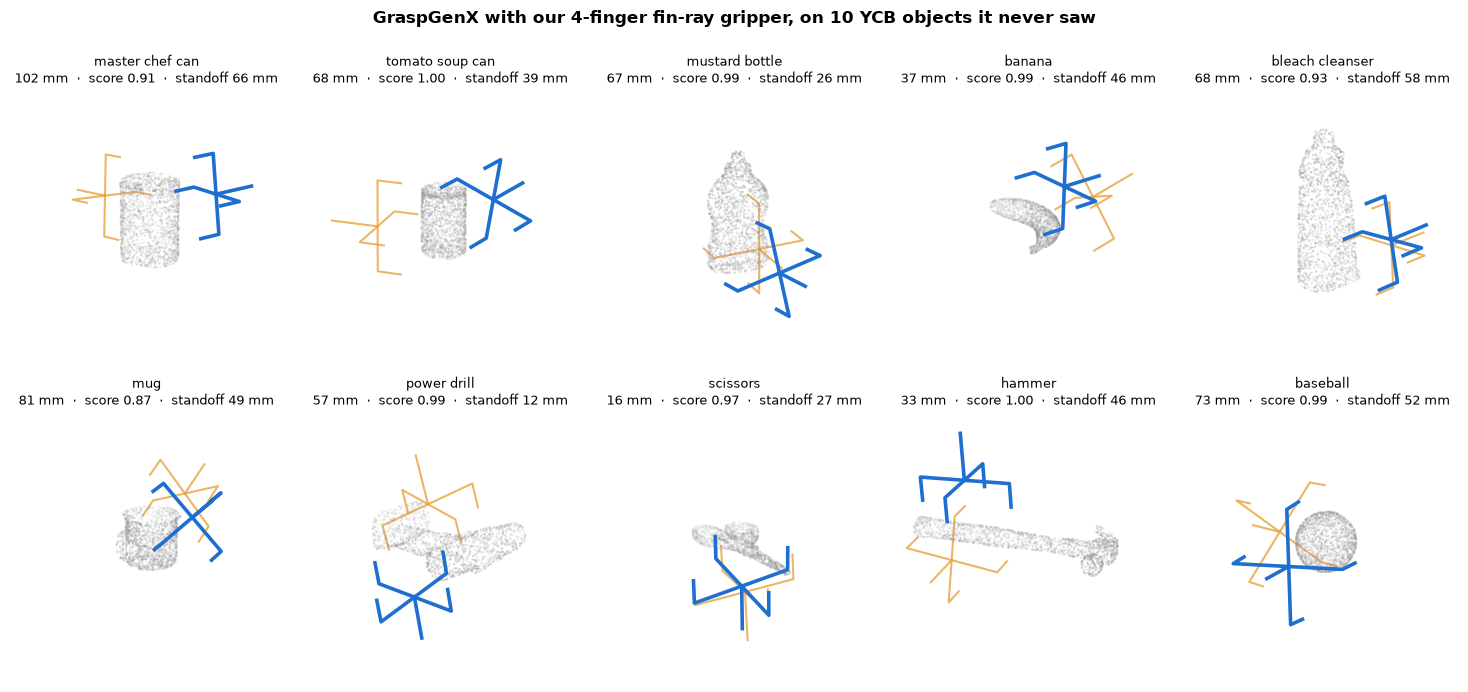

In [8]:
def wireframe(pose):
    """The four fingers, plus the stem back to the gripper base."""
    segs = [[[0, 0, Z_BACK], [0, 0, 0]]]                       # stem
    for fx, fy in FINGERS:
        segs.append([[0, 0, Z_BACK],
                     [REACH*fx, REACH*fy, Z_BACK],             # spoke out to the knuckle
                     [REACH*fx, REACH*fy, Z_TIP]])             # the finger itself
    return [(pose @ np.c_[np.array(s), np.ones(len(s))].T).T[:, :3] for s in segs]


fig = plt.figure(figsize=(15, 7.0))
for i, name in enumerate(OBJECTS):
    r = results[name]
    top2 = np.argsort(-r["conf"])[:2]

    ax = fig.add_subplot(2, 5, i+1, projection="3d")
    ax.scatter(*r["pts"][::2].T, s=2.5, c="0.6", alpha=.55, linewidths=0)
    for rank, k in enumerate(reversed(top2)):
        best = rank == len(top2)-1
        for seg in wireframe(r["poses"][k]):
            ax.plot(*seg.T, color="#1f6fd0" if best else "#e8a33d",
                    lw=2.6 if best else 1.5, alpha=1.0 if best else .8,
                    zorder=3 if best else 2)
    contacts = four_contacts(r["poses"][top2[0]], r["dense"])
    if contacts is not None:
        ax.scatter(*contacts.T, s=34, c="#c0392b", edgecolors="white", lw=.6, zorder=5)

    lim = max(np.abs(r["pts"]).max(),
              max(np.abs(s).max() for s in wireframe(r["poses"][top2[0]])))
    for setter in (ax.set_xlim, ax.set_ylim, ax.set_zlim): setter(-lim, lim)
    ax.set_box_aspect((1, 1, 1), zoom=1.5)
    ax.view_init(elev=20, azim=45); ax.set_axis_off()
    ax.set_title(f"{name[4:].replace('_',' ')}\n"
                 f"{r['size'].min():.0f} mm  ·  score {r['conf'].max():.2f}  ·  "
                 f"standoff {r['standoff'][top2[0]]:.0f} mm",
                 fontsize=9.5, pad=-4)

fig.suptitle("GraspGenX with our 4-finger fin-ray gripper, on 10 YCB objects it never saw",
             fontsize=12, fontweight="bold", y=.995)
fig.subplots_adjust(top=.885, bottom=.035, left=.01, right=.99, wspace=0, hspace=.18)
fig.savefig(OUT/"graspgenx_unseen_objects_4f.png", dpi=150, facecolor="white")
plt.show()

## 8. The same objects with the 2-finger gripper

The standoff numbers only mean something next to a control. The 2-finger gripper has the same
fingers at the same depth — the *only* thing that changes in what GraspGenX is told is the y
extent of the swept box, 30 mm instead of 148 mm.

In [9]:
two_f = params["grippers"]["2-finger"]
sampler_2f = GraspGenXSampler(
    cfg, model=sampler.model,
    gripper_info=make_sweep_volume_gripper_info(
        two_f["extents_open"], two_f["offset_open"],
        two_f["extents_mid"],  two_f["offset_mid"], name="finray_2f"))

rows = []
for name in OBJECTS:
    r = results[name]
    poses_2f, _ = GraspGenXSampler.run_inference(
        r["pts"], sampler_2f, grasp_threshold=-1.0, num_grasps=200,
        topk_num_grasps=20, remove_outliers=False)
    s2 = np.array([standoff_mm(T, r["dense"]) for T in poses_2f.cpu().numpy()])
    rows.append(dict(object=name[4:].replace("_", " "),
                     short_mm=round(r["size"].min()),
                     standoff_2f_mm=round(float(np.median(s2)), 1),
                     reach_2f=round(float(np.mean(s2 <= 0)), 2),
                     standoff_4f_mm=round(float(np.median(r["standoff"])), 1),
                     reach_4f=round(float(np.mean(r["standoff"] <= 0)), 2)))

import pandas as pd
table = pd.DataFrame(rows)
table.to_csv(OUT/"graspgenx_unseen_objects_4f.csv", index=False)
print(f"median standoff — 2-finger {table.standoff_2f_mm.median():.1f} mm, "
      f"4-finger {table.standoff_4f_mm.median():.1f} mm")
print(f"grasps that reach the object — 2-finger {table.reach_2f.mean():.0%}, "
      f"4-finger {table.reach_4f.mean():.0%}\n")
table

2026-09-11 09:25:53,403 - graspgenx.grasp_server - INFO - Confidences min: 0.01952, max: 0.86762


2026-09-11 09:25:53,404 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:25:53,406 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 1, total grasps: 20


2026-09-11 09:25:53,406 - graspgenx.grasp_server - INFO - Time taken for inference: 0.9689600467681885 seconds


2026-09-11 09:25:54,252 - graspgenx.grasp_server - INFO - Confidences min: 0.02961, max: 0.87360


...

2026-09-11 09:26:11,095 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-11 09:26:11,097 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 2, total grasps: 40


2026-09-11 09:26:11,097 - graspgenx.grasp_server - INFO - Time taken for inference: 0.7800037860870361 seconds


median standoff — 2-finger -20.4 mm, 4-finger 29.1 mm
grasps that reach the object — 2-finger 68%, 4-finger 18%



,object,short_mm,standoff_2f_mm,reach_2f,standoff_4f_mm,reach_4f
0,master chef can,102,-7.6,0.75,25.2,0.07
1,tomato soup can,68,-25.4,0.62,31.1,0.33
2,mustard bottle,67,-5.2,0.57,23.7,0.07
3,banana,37,-4.5,0.62,41.8,0.03
4,bleach cleanser,68,-21.2,0.68,46.9,0.07
5,mug,81,-23.4,0.62,19.0,0.07
6,power drill,57,-23.0,0.62,31.5,0.38
7,scissors,16,-19.6,0.80,27.2,0.00
8,hammer,33,-31.1,0.95,-25.3,0.70
9,baseball,73,-4.7,0.55,39.2,0.07


## 9. What this shows

**GraspGenX cannot plan for our 4-finger gripper, and it does not know that it cannot.**

It returns grasps with confidences up to 1.00 for every object. But the fingers land tens of
millimetres beyond the object: the gripper closes on empty air, at a pose the model scores as
near-perfect.

The cause is in the interface, not the objects. GraspGenX conditions on a **swept-volume box**.
Our 2-finger gripper is a 148 x 30 x 38 mm box; the 4-finger version is 148 x **148** x 38 mm,
because the second pair of fingers closes along the other axis. Nothing in those twelve numbers
says "four fingers" — a square box reads to the model as a much bulkier gripper, so it backs the
pose off to keep the object clear of it. The 2-finger box, on the same objects with the same
fingers, does not have this problem.

**What this means for Stage 3.** GraspGenX is usable for the 2-finger gripper and not for the
4-finger one. Getting 4-finger grasps out of it would need either a different conditioning
(swept volume is the wrong representation for a non-parallel-jaw hand), or a post-step that takes
the 2-finger pose and re-solves the second finger pair ourselves.

**Caveat.** Standoff is geometry, not a simulated grasp: it says the fingers do not touch the
object, which is enough to rule these grasps out, but a standoff at or below zero would still not
prove a grasp holds.